# Лабораторная работа 4
> - **Предмет:** МОСИИ
> - **Студент:** Руденко Андрей Артемович
> - **Группа:** М9125-01.04.02МКТ

**Цель работы:** Улучшение свёрточной нейросети для классификации чистых и грязных тарелок.

In [1]:
import numpy as np
import pandas as pd
import os
import zipfile
import shutil
from tqdm import tqdm

import torch
import torchvision
import matplotlib.pyplot as plt
import time
import copy

from torchvision import transforms, models

## Данные

In [2]:
with zipfile.ZipFile('plates.zip', 'r') as zip_obj:
    zip_obj.extractall('.')

data_root = 'plates'
print(os.listdir(data_root))

['.DS_Store', '__MACOSX', 'test', 'train', 'plates']


In [3]:
train_dir = 'train'
val_dir = 'val'

class_names = ['cleaned', 'dirty']

for dir_name in [train_dir, val_dir]:
    for class_name in class_names:
        os.makedirs(os.path.join(dir_name, class_name), exist_ok=True)

for class_name in class_names:
    source_dir = os.path.join(data_root, 'train', class_name)
    for i, file_name in enumerate(tqdm(sorted(os.listdir(source_dir)))):
        if i % 6 != 0:
            dest_dir = os.path.join(train_dir, class_name)
        else:
            dest_dir = os.path.join(val_dir, class_name)
        shutil.copy(os.path.join(source_dir, file_name), os.path.join(dest_dir, file_name))

100%|██████████████████████████████████████████████████████████████████████████████| 21/21 [00:00<00:00, 11444.96it/s]


In [4]:
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = torchvision.datasets.ImageFolder(train_dir, train_transforms)
val_dataset = torchvision.datasets.ImageFolder(val_dir, val_transforms)

batch_size = 8
train_dataloader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_dataloader = torch.utils.data.DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

In [5]:
len(train_dataloader), len(train_dataset)

(5, 34)

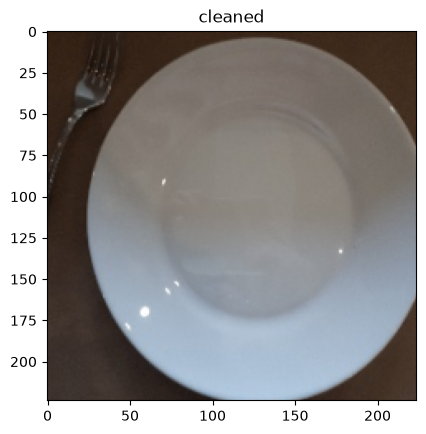

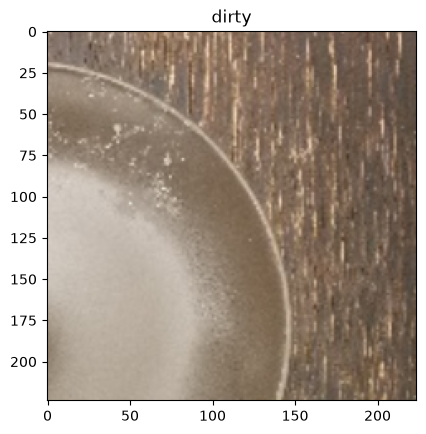

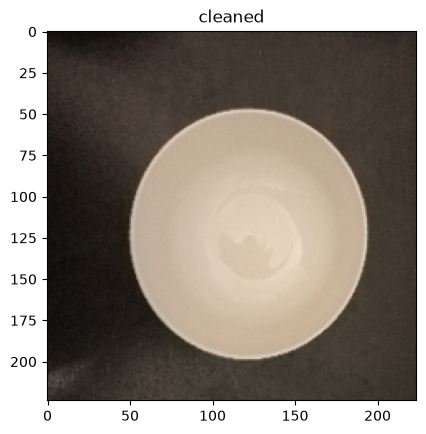

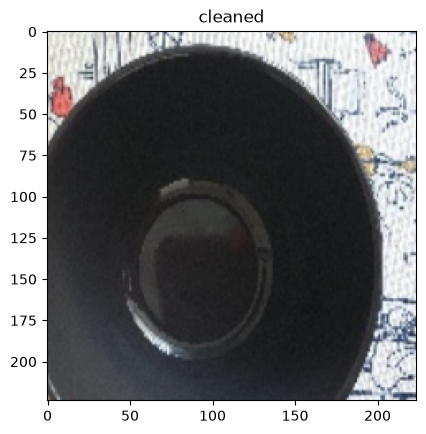

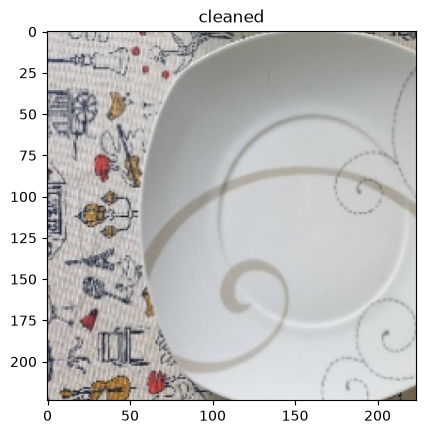

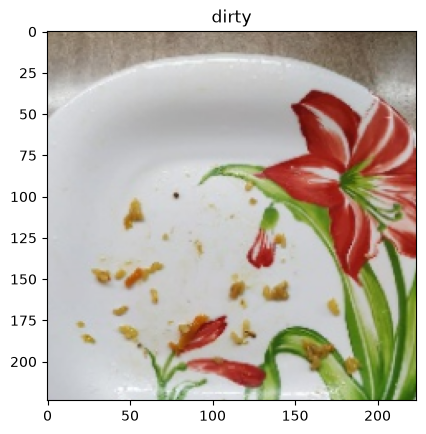

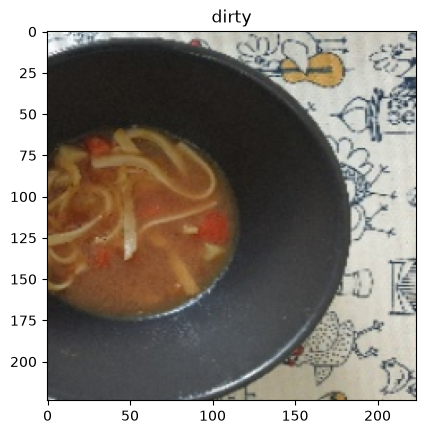

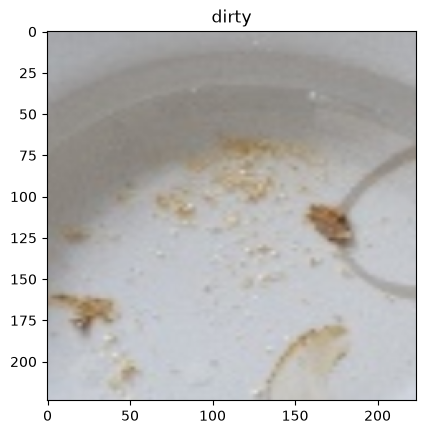

In [6]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

def show_input(input_tensor, title=''):
    image = input_tensor.permute(1, 2, 0).numpy()
    image = std * image + mean
    plt.imshow(image.clip(0, 1))
    plt.title(title)
    plt.show()
    plt.pause(0.001)

X_batch, y_batch = next(iter(train_dataloader))

for x_item, y_item in zip(X_batch, y_batch):
    show_input(x_item, title=class_names[y_item])

## Baseline

In [7]:
def train_model(model, loss, optimizer, scheduler, num_epochs):
    for epoch in range(num_epochs):
        print('Epoch {}/{}:'.format(epoch, num_epochs - 1), flush=True)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                dataloader = train_dataloader
                scheduler.step()
                model.train()  # Set model to training mode
            else:
                dataloader = val_dataloader
                model.eval()   # Set model to evaluate mode

            running_loss = 0.
            running_acc = 0.

            # Iterate over data.
            for inputs, labels in tqdm(dataloader):
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                # forward and backward
                with torch.set_grad_enabled(phase == 'train'):
                    preds = model(inputs)
                    loss_value = loss(preds, labels)
                    preds_class = preds.argmax(dim=1)

                    # backward + optimize only if in training phase
                    if phase == 'train':
                        loss_value.backward()
                        optimizer.step()

                # statistics
                running_loss += loss_value.item()
                running_acc += (preds_class == labels.data).float().mean()

            epoch_loss = running_loss / len(dataloader)
            epoch_acc = running_acc / len(dataloader)

            print('{} Loss: {:.4f} Acc: {:.4f}'.format(phase, epoch_loss, epoch_acc), flush=True)

    return model

In [8]:
torch.manual_seed(42)

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Disable grad for all conv layers
for param in model.parameters():
    param.requires_grad = False

model.fc = torch.nn.Linear(model.fc.in_features, 2)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1.0e-3)

# Decay LR by a factor of 0.1 every 7 epochs
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

In [9]:
train_model(model, loss, optimizer, scheduler, num_epochs=10);

Epoch 0/9:


/tmp/ipykernel_37115/2546526572.py:9: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
100%|███████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  7.40it/s]

train Loss: 0.7865 Acc: 0.3500



100%|███████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  3.74it/s]

val Loss: 0.7119 Acc: 0.6667
Epoch 1/9:


...

val Loss: 0.5795 Acc: 0.6667
Epoch 9/9:



100%|███████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  8.85it/s]

train Loss: 0.4893 Acc: 0.7250



100%|███████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  9.76it/s]

val Loss: 0.5579 Acc: 0.6667


## Предсказание для теста

In [10]:
test_dir = 'test'

class ImageFolderWithPaths(torchvision.datasets.ImageFolder):
    def __getitem__(self, index):
        original_tuple = super(ImageFolderWithPaths, self).__getitem__(index)
        path = self.imgs[index][0]
        tuple_with_path = (original_tuple + (path,))
        return tuple_with_path

if not os.path.exists(test_dir):
    shutil.copytree(os.path.join(data_root, 'test'), os.path.join(test_dir, 'unknown'))
test_dataset = ImageFolderWithPaths(test_dir, val_transforms)

test_dataloader = torch.utils.data.DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

In [11]:
model.eval()

test_predictions = []
test_img_paths = []
for inputs, labels, paths in tqdm(test_dataloader):
    inputs = inputs.to(device)
    labels = labels.to(device)
    with torch.set_grad_enabled(False):
        preds = model(inputs)
    test_predictions.append(
        torch.nn.functional.softmax(preds, dim=1)[:,1].data.cpu().numpy())
    test_img_paths.extend(paths)

test_predictions = np.concatenate(test_predictions)

100%|█████████████████████████████████████████████████████████████████████████████████| 93/93 [00:10<00:00,  8.83it/s]


In [12]:
submission_df = pd.DataFrame.from_dict({'id': test_img_paths, 'label': test_predictions})
submission_df['label'] = submission_df['label'].map(lambda pred: 'dirty' if pred > 0.5 else 'cleaned')
submission_df['id'] = submission_df['id'].map(lambda path: os.path.splitext(os.path.basename(path))[0])
submission_df.set_index('id', inplace=True)
submission_df.head(n=6)

,label
id,
0000,dirty
0001,dirty
0002,dirty
0003,dirty
0004,dirty
0005,dirty


In [13]:
submission_df.to_csv('submission_baseline.csv')

## Вывод работы baseline

Baseline на Kaggle дал 0.69086, у преподавателя с той же моделью было 0.77553. Модель одна, разница из-за случайности: обучающих картинок всего 34, и результат сильно зависит от того, какие обрезки попали в обучение. Модель почти все тарелки считает грязными: 664 из 744.

## ResNet-18 с дообучением

Что поменял относительно baseline:
- дообучаю последний свёрточный блок `layer4`, а не только последний слой, чтобы сеть подстроилась под тарелки;
- больше аугментаций: тарелка круглая, поэтому её можно поворачивать и отражать по вертикали, плюс меняю яркость и контраст;
- 20 эпох вместо 10 и шаг поменьше (`lr = 3e-4`), так как обучается больше весов.

In [14]:
torch.manual_seed(42)

train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
train_dataset = torchvision.datasets.ImageFolder(train_dir, train_transforms)
train_dataloader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model.parameters():
    param.requires_grad = False
for param in model.layer4.parameters():
    param.requires_grad = True
model.fc = torch.nn.Linear(model.fc.in_features, 2)
model = model.to(device)

loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=3.0e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

train_model(model, loss, optimizer, scheduler, num_epochs=20);

Epoch 0/19:


/tmp/ipykernel_37115/2546526572.py:9: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
100%|███████████████████████████████████████████████████████████████████████████████████| 5/5 [00:01<00:00,  4.53it/s]

train Loss: 0.5586 Acc: 0.7000



100%|███████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 13.41it/s]

val Loss: 0.6182 Acc: 0.8333
Epoch 1/19:


...

val Loss: 0.3688 Acc: 0.8333
Epoch 19/19:



100%|███████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  7.40it/s]

train Loss: 0.3640 Acc: 0.9000



100%|███████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 15.65it/s]

val Loss: 0.3797 Acc: 0.8333


Предсказание для теста делаю так же, как в baseline, поэтому вынес его в функцию.

In [15]:
def make_submission(model, file_name):
    model.eval()
    test_predictions = []
    test_img_paths = []
    for inputs, labels, paths in tqdm(test_dataloader):
        inputs = inputs.to(device)
        with torch.no_grad():
            preds = model(inputs)
        test_predictions.append(torch.nn.functional.softmax(preds, dim=1)[:, 1].cpu().numpy())
        test_img_paths.extend(paths)

    submission_df = pd.DataFrame({'id': test_img_paths, 'label': np.concatenate(test_predictions)})
    submission_df['label'] = submission_df['label'].map(lambda pred: 'dirty' if pred > 0.5 else 'cleaned')
    submission_df['id'] = submission_df['id'].map(lambda path: os.path.splitext(os.path.basename(path))[0])
    submission_df.set_index('id', inplace=True)
    submission_df.to_csv(file_name)
    print(submission_df['label'].value_counts())


make_submission(model, 'submission_resnet18.csv')

100%|█████████████████████████████████████████████████████████████████████████████████| 93/93 [00:09<00:00, 10.08it/s]

label
dirty      579
cleaned    165
Name: count, dtype: int64


## Вывод работы ResNet-18 с дообучением

На Kaggle 0.83467: выше 0.77, выше baseline преподавателя (0.77553) и нашего baseline (0.69086). Дообучение последнего блока помогло сети подстроиться под тарелки, а повороты и отражения дали больше разных картинок из всего 34 обучающих. Модель теперь чаще находит чистые тарелки: 165 против 80 у baseline.

## ResNet-50 с дообучением

То же самое, что в прошлом варианте, но на более глубокой сети ResNet-50.

In [16]:
torch.manual_seed(42)
train_dataloader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)

model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
for param in model.parameters():
    param.requires_grad = False
for param in model.layer4.parameters():
    param.requires_grad = True
model.fc = torch.nn.Linear(model.fc.in_features, 2)
model = model.to(device)

loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=3.0e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

train_model(model, loss, optimizer, scheduler, num_epochs=20);
make_submission(model, 'submission_resnet50.csv')

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /home/anko/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|████████████████████████████████████████████████████████████████████████████| 97.8M/97.8M [00:14<00:00, 7.08MB/s]


Epoch 0/19:


/tmp/ipykernel_37115/2546526572.py:9: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
100%|███████████████████████████████████████████████████████████████████████████████████| 5/5 [00:01<00:00,  2.99it/s]

train Loss: 0.7199 Acc: 0.4750


...

train Loss: 0.0676 Acc: 1.0000



100%|███████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  5.49it/s]

val Loss: 0.4282 Acc: 0.8333



100%|█████████████████████████████████████████████████████████████████████████████████| 93/93 [00:23<00:00,  4.01it/s]

label
dirty      668
cleaned     76
Name: count, dtype: int64


## Вывод работы ResNet-50 с дообучением

0.73655, хуже ResNet-18, хотя сеть глубже. Скорее всего, для 34 картинок она слишком большая: в её последнем блоке намного больше весов, и она подстраивается под обучающие картинки, а не учится общему. Как и baseline, она почти все тарелки считает грязными (668 из 744).

## ResNet-50 с усреднением по поворотам

Та же обученная ResNet-50, но каждую тестовую картинку показываю модели 4 раза: как есть, отражённой по горизонтали, по вертикали и повёрнутой на 90°. Вероятности усредняю. Тарелка от этого не меняется, а случайные ошибки модели на одном варианте картинки сглаживаются.

In [17]:
def make_submission_tta(model, file_name):
    model.eval()
    test_predictions = []
    test_img_paths = []
    for inputs, labels, paths in tqdm(test_dataloader):
        inputs = inputs.to(device)
        with torch.no_grad():
            versions = [inputs, inputs.flip(3), inputs.flip(2), inputs.rot90(1, dims=(2, 3))]
            probs = [torch.nn.functional.softmax(model(x), dim=1)[:, 1] for x in versions]
        test_predictions.append(torch.stack(probs).mean(dim=0).cpu().numpy())
        test_img_paths.extend(paths)

    submission_df = pd.DataFrame({'id': test_img_paths, 'label': np.concatenate(test_predictions)})
    submission_df['label'] = submission_df['label'].map(lambda pred: 'dirty' if pred > 0.5 else 'cleaned')
    submission_df['id'] = submission_df['id'].map(lambda path: os.path.splitext(os.path.basename(path))[0])
    submission_df.set_index('id', inplace=True)
    submission_df.to_csv(file_name)
    print(submission_df['label'].value_counts())


make_submission_tta(model, 'submission_resnet50_tta.csv')

100%|█████████████████████████████████████████████████████████████████████████████████| 93/93 [01:27<00:00,  1.06it/s]

label
dirty      675
cleaned     69
Name: count, dtype: int64


## Вывод работы ResNet-50 с усреднением по поворотам

0.72983, почти как без усреднения. Усреднение сглаживает случайные ошибки, но не исправляет плохо обученную модель: если она ошибается, то на всех четырёх вариантах картинки.

## Технический отчёт

| Модель | Accuracy на Kaggle |
|---|---|
| Baseline преподавателя | 0.77553 |
| Baseline, наш запуск | 0.69086 |
| **ResNet-18 с дообучением** | **0.83467** |
| ResNet-50 с дообучением | 0.73655 |
| ResNet-50 + усреднение по поворотам | 0.72983 |

Перебить baseline удалось ResNet-18 с дообучением последнего блока, аугментациями и 20 эпохами: 0.83467 против 0.77553 у преподавателя. Более глубокая ResNet-50 с теми же настройками оказалась хуже, на таком маленьком датасете большая сеть не помогает. Усреднение по поворотам на тесте тоже ничего не дало.

Baseline при одной и той же модели дал 0.69 у нас и 0.78 у преподавателя, то есть на 34 картинках результат сильно зависит от случайности. Поэтому score лучше сравнивать с запасом, а не по сотым.

![](kaggle_score.png)